# 03 - Noise-residual features
---

## 1. Imports


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

sys.path.insert(0, str(Path.cwd().parent))
from src.features import load_images, noise_residual, rapsd

## 2. Data loading


In [2]:
ROOT = Path.cwd().parent
train_real_dir = ROOT / "data" / "cifake" / "train" / "REAL"
train_fake_dir = ROOT / "data" / "cifake" / "train" / "FAKE"
test_real_dir = ROOT / "data" / "cifake" / "test" / "REAL"
test_fake_dir = ROOT / "data" / "cifake" / "test" / "FAKE"

### 2.1 Training set

In [3]:
x_real = load_images(train_real_dir)
x_fake = load_images(train_fake_dir)

x_train = np.concatenate([x_real, x_fake])
y_train = np.array([0] * len(x_real) + [1] * len(x_fake))

print("x :", x_train.shape, "| y :", np.bincount(y_train))

x : (100000, 32, 32) | y : [50000 50000]


### 2.2 Test set

In [4]:
x_real = load_images(test_real_dir)
x_fake = load_images(test_fake_dir)

x_test = np.concatenate([x_real, x_fake])
y_test = np.array([0] * len(x_real) + [1] * len(x_fake))

print("x :", x_test.shape, "| y :", np.bincount(y_test))

x : (20000, 32, 32) | y : [10000 10000]


### 2.3 train test split

In [5]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("train:", x_train.shape, "| val:", x_val.shape)

train: (80000, 32, 32) | val: (20000, 32, 32)


## 3. Noise residual extraction

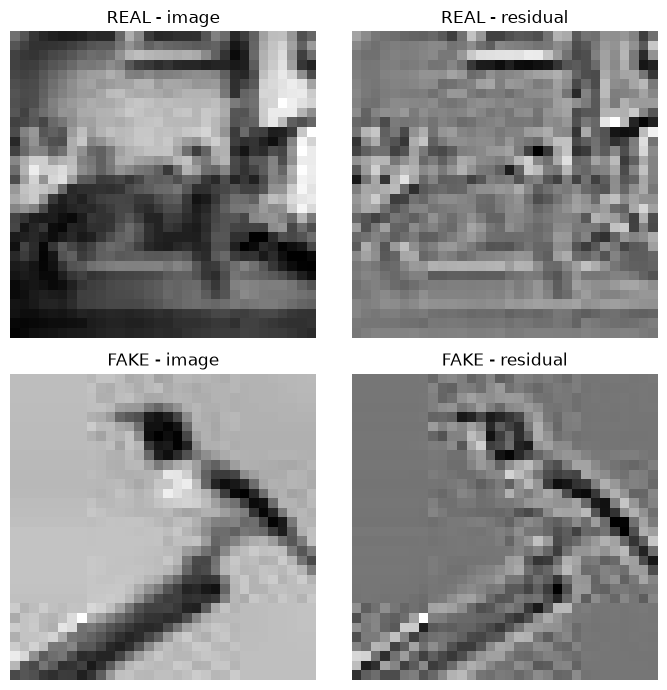

In [6]:
img_real = x_train[y_train == 0][0]
img_fake = x_train[y_train == 1][0]

fig, axes = plt.subplots(2, 2, figsize=(7, 7))
axes[0, 0].imshow(img_real, cmap="gray")
axes[0, 0].set_title("REAL - image")

axes[0, 1].imshow(noise_residual(img_real), cmap="gray")  
axes[0, 1].set_title("REAL - residual")

axes[1, 0].imshow(img_fake, cmap="gray")     
axes[1, 0].set_title("FAKE - image")

axes[1, 1].imshow(noise_residual(img_fake), cmap="gray")   
axes[1, 1].set_title("FAKE - residual")

for a in axes.ravel():
    a.axis("off")
fig.tight_layout()
plt.show()

## 4. Exploratory analysis - residual spectrum per class


In [7]:
def noise_features(images):
    features = []
    for image in images:
        res = noise_residual(image)      
        features.append(rapsd(res))
    return np.array(features)

In [8]:
features_noise_train = noise_features(x_train)
features_noise_val = noise_features(x_val)

print("features_noise_train :", features_noise_train.shape)
print("features_noise_val :", features_noise_val.shape)

features_noise_train : (80000, 23)
features_noise_val : (20000, 23)


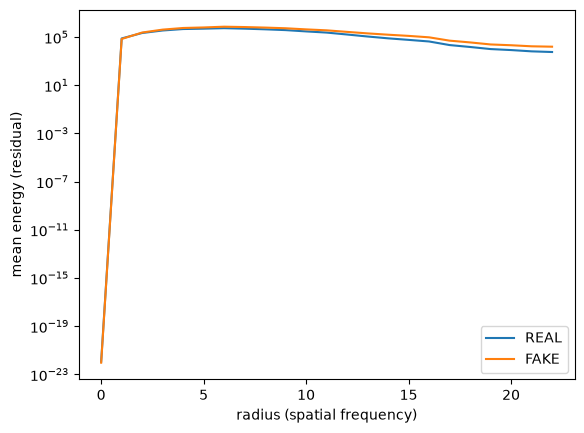

In [9]:
noise_real = features_noise_train[y_train == 0]
noise_fake = features_noise_train[y_train == 1]

mean_noise_real = noise_real.mean(axis=0)
mean_noise_fake = noise_fake.mean(axis=0)

x = np.arange(len(mean_noise_real))   

plt.semilogy(x, mean_noise_real, label="REAL")
plt.semilogy(x, mean_noise_fake, label="FAKE")

plt.xlabel("radius (spatial frequency)")
plt.ylabel("mean energy (residual)")
plt.legend()
plt.show()

## 5. Model

In [10]:
scaler_noise = StandardScaler()
x_noise_train = scaler_noise.fit_transform(features_noise_train)
x_noise_val = scaler_noise.transform(features_noise_val)

In [11]:
model_noise = XGBClassifier(n_estimators=200,
                           max_depth=5,
                          random_state=42, 
                          n_jobs=-1, 
                          eval_metric="logloss"
)
model_noise.fit(x_noise_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [12]:
acc = accuracy_score(y_val, model_noise.predict(x_noise_val))
print("Residual-feature validation accuracy:", acc)

Residual-feature validation accuracy: 0.8095


## 6. Comparison with the spectral baseline


In [13]:
def spectral_features(images):
    features = []
    for img in images:
        profile = rapsd(img)
        features.append(profile)
    features = np.array(features)
    return features

In [14]:
def xgb(x_train, x_val):
    scaler = StandardScaler()
    x_train  = scaler.fit_transform(x_train)
    x_val = scaler.transform(x_val)
    model = XGBClassifier(n_estimators=200, 
                          max_depth=5,
                          random_state=42, 
                          n_jobs=-1, 
                          eval_metric="logloss"
    )
    model.fit(x_train, y_train)
    pred_val_xgb = model.predict(x_val)
    acc = accuracy_score(y_val, pred_val_xgb)
    return acc

In [15]:
spec_train = spectral_features(x_train)
spec_val = spectral_features(x_val)

noise_train = noise_features(x_train) 
noise_val = noise_features(x_val)

comb_train = np.concatenate([spec_train, noise_train], axis=1)
comb_val = np.concatenate([spec_val, noise_val], axis=1)

print("Spectral features only :", xgb(spec_train, spec_val))
print("Residual features only :", xgb(noise_train, noise_val))
print("Combined features      :", xgb(comb_train, comb_val))

Spectral features only : 0.7921
Residual features only : 0.8095
Combined features      : 0.8255


## 7. Final test

In [16]:
spec_test = spectral_features(x_test)
noise_test = noise_features(x_test)
comb_test = np.concatenate([spec_test, noise_test], axis=1)

scaler_final = StandardScaler()
comb_train_scaled = scaler_final.fit_transform(comb_train)
comb_test_scaled  = scaler_final.transform(comb_test)

model_comb = XGBClassifier(n_estimators=200,
                            max_depth=5,
                            random_state=42, 
                            n_jobs=-1, 
                            eval_metric="logloss"
)

model_comb.fit(comb_train_scaled, y_train)
y_pred = model_comb.predict(comb_test_scaled)
acc_test = accuracy_score(y_test, y_pred)

print("FINAL accuracy on the official test set (combined):", acc_test)

FINAL accuracy on the official test set (combined): 0.82755


## 8. Conclusion

### Summary
We extracted a noise residual from each image (the image minus its Gaussian-blurred version), then applied the same radial power spectrum (RAPSD) to this residual. This gives a new family of features, based on the image noise instead of the raw image.

### Results (validation)
| Features | Validation accuracy |
|----------|---------------------|
| Spectral only (notebook 02) | 0.792 |
| Residual only | 0.810 |
| Combined (spectral + residual) | 0.826 |

On the official test set, the combined model reaches 0.828, which is higher than the 0.797 of the spectral model from notebook 02.

### Interpretation
The residual features alone already improve the performance, which shows that studying the frequencies of the image noise brings more information than studying the frequencies of the image without denoising. Moreover, combining the two features improves the performance even further, so the two features do not cover exactly the same information, they are therefore complementary. Denoising the images beforehand therefore adds value to the model's performance.


### Limitations
- The denoising uses a simple Gaussian filter; a more advanced method (median, Non-Local Means) might isolate the noise even better.
- As in notebook 02, the signature is specific to the generator used in CIFAKE (Stable Diffusion v1.4).

### Future work
- Try other denoising methods and compare.